# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [2]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    plot_raw,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [3]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run** (`plot_raw(g)`); **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [3]:
g = run(<id>)                 # open + re-form via helpers
plot_raw(g)                   # raw view FIRST — rails/clipping, dead channels, streaks live here

In [4]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — gate C liveness: `gate-current-sanity-check` (B = 0, V_si = 0, T = 1.17 K)

**Read:** device alive on the provided contacts — drain current 9.86–9.94 nA (full 10 nA bias, R_2T ≪ 100 MΩ), Rxx(B_1−B_2) 60–330 Ω. No leakage: both gate currents stay at their pA offsets (BG +25 pA flat; TG −100 pA, drifting to 0 pA over V_tg = 0.4→1.0 V — a ~100 pA/0.6 V change, within the 2400's 1 µA-range offset behaviour and far below the 1 nA trip; watch it on the map, don't alarm). **Gate C: pass.** Two resistance maxima on each gate — TG: −0.21 V (322 Ω) and +0.11 V (244 Ω); BG: −0.26 V (302 Ω) and +0.14 V (273 Ω) — the same pair seen through both gates (position ratios 0.81 / 0.79 ≈ c_bg/c_tg; geometry prior 0.86). Two CNPs in series between B_1 and B_2 → two regions of different intrinsic doping (Δn ≈ 0.6×10¹² from the geometry prior), weak contrast (~3× over the metallic floor). Whether they are two flake domains or a contact-adjacent region is a gatemap question (parallel ridges vs not); series-mosaic is a stacking-read confound to carry forward.


run 0 k_2400_tg +0.00->+1.00 V: R 87-244 Ohm (max at +0.110 V), I_drain 9.86-9.94 nA, I_tg -106..+14 pA, I_bg +15..+34 pA, T 1.166 K, interrupted=False
run 1 k_2400_tg +0.00->-0.30 V: R 201-322 Ohm (max at -0.210 V), I_drain 9.86-9.93 nA, I_tg -112..-92 pA, I_bg +15..+34 pA, T 1.166 K, interrupted=False
run 2 k_2400_bg +0.00->+2.00 V: R 63-273 Ohm (max at +0.140 V), I_drain 9.86-9.93 nA, I_tg -109..-91 pA, I_bg +16..+38 pA, T 1.166 K, interrupted=False
run 3 k_2400_bg +0.00->-1.30 V: R 86-302 Ohm (max at -0.260 V), I_drain 9.85-9.93 nA, I_tg -109..-89 pA, I_bg +13..+33 pA, T 1.166 K, interrupted=False


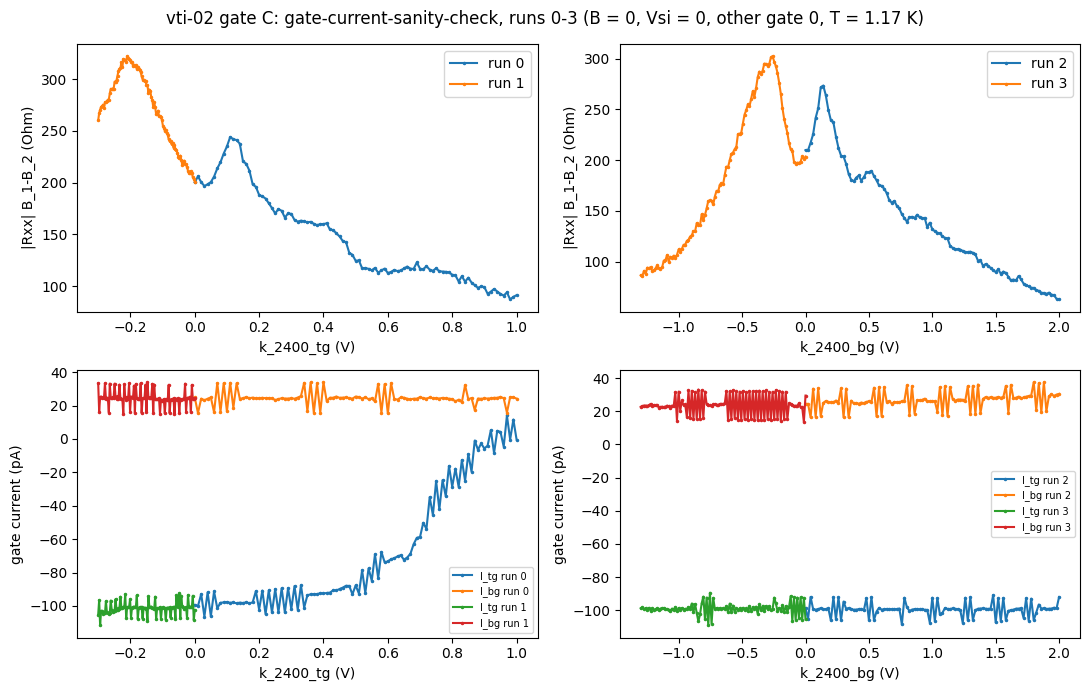

In [6]:
# Gate C — runs 0-3 (gate-current-sanity-check). Raw first: R = (sr1_X/gain)/I_drain per point, gate currents.
from hera.analysis import resolve_channels
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
peaks = {}
for i in range(4):
    r = run(i)
    ch = {c.cid: c for c in resolve_channels(r.meta)}
    V = r.col(r.swept_axis)
    I = r.col("sr0_X") / ch["sr0"].gain
    R = np.abs((r.col("sr1_X") / ch["sr1"].gain) / I)
    i_tg, i_bg = r.col("k_2400_tg_curr"), r.col("k_2400_bg_curr")
    gate = r.swept_axis.replace("_volt", "")
    k = np.argmax(R); peaks[i] = (gate, V[k], R[k])
    print(f"run {i} {gate} {V[0]:+.2f}->{V[-1]:+.2f} V: R {R.min():.0f}-{R.max():.0f} Ohm (max at {V[k]:+.3f} V), "
          f"I_drain {I.min()*1e9:.2f}-{I.max()*1e9:.2f} nA, I_tg {i_tg.min()*1e12:+.0f}..{i_tg.max()*1e12:+.0f} pA, "
          f"I_bg {i_bg.min()*1e12:+.0f}..{i_bg.max()*1e12:+.0f} pA, T {r.col('T_sample').mean():.3f} K, interrupted={r.interrupted}")
    a = ax[0, 0] if "tg" in gate else ax[0, 1]
    a.plot(V, R, ".-", ms=3, label=f"run {i}"); a.set_xlabel(gate + " (V)"); a.set_ylabel("|Rxx| B_1-B_2 (Ohm)"); a.legend()
    b = ax[1, 0] if "tg" in gate else ax[1, 1]
    b.plot(V, i_tg * 1e12, ".-", ms=3, label=f"I_tg run {i}"); b.plot(V, i_bg * 1e12, ".-", ms=3, label=f"I_bg run {i}")
    b.set_xlabel(gate + " (V)"); b.set_ylabel("gate current (pA)"); b.legend(fontsize=7)
fig.suptitle("vti-02 gate C: gate-current-sanity-check, runs 0-3 (B = 0, Vsi = 0, other gate 0, T = 1.17 K)")
fig.tight_layout(); plt.show()


## Run 5 — 0 T gatemap (`gatemap`) → `cnp-and-dline-calibration`

Raw map (log R, TG fast [−0.3, +1.0] × BG slow [−1.3, +1.2], 20 × 40 mV, sr1 100 µV; run 4 was the same map aborted at 3 min when the ridge railed at 2 kΩ). **Read:** one dominant CNP ridge (A) running from (V_tg, V_bg) ≈ (+1.0, −1.3) to (−0.3, +0.45), plus a fainter **parallel** ridge (B) ≈ 0.19 V lower in V_tg — the second peak of runs 0–3. Ridge A's resistance is 240 Ω near D ≈ 0 and grows to ~2.4 kΩ at raw D ≈ +0.25 V/nm (saturating beyond), i.e. a D-tunable gap; **not a stacking read** (investigation Step 1 addendum: three candidate parents). Fits (ridge position = V_tg vs V_bg rows, so −slope = c_bg/c_tg): ridge A in the operating window |V_bg| < 0.5: slope −0.773 (rms 19 mV); high-D rows: −0.763 (rms 6 mV); ridge B: −0.69 (8 rows, rms 13 mV). **Calibration:** ratio c_bg/c_tg = 0.773 (data-calibrated; prior 0.864, −11 % — plausible hBN-thickness error, not a transposition); c_tg anchored at the 9.5 nm prior (absolute scale = geometry prior, pending a lever-arm check); n_offset = −0.089×10¹²; **D_offset from the R_CNP(D) symmetry** (vertex of the ridge-A resistance minimum, ≈ +0.012 raw) — the one feature that physically locates D = 0. Region B is electron-doped by 0.43×10¹² relative to A: a series-mosaic confound (same template expected, 13 % higher n at the fan density — extra tones at ×1.13). Realized D = 0 window inside the validators: **n = −1.27 … +3.27×10¹²** (TG-limited on both ends). Channel arithmetic: R = (sr1_X/1)/(sr0_X/−1e6).


run 5: 63 rows x 66; R 50-3068 Ohm; prior c_bg/c_tg = 0.864
--- ridge A (main) ---
A all rows: 29/30 rows, Vbg [-2.00,+2.00]: Vtg = -0.7308 Vbg +0.0474; c_bg/c_tg = 0.731; rms 15.5 mV
A high-D rows: 16/16 rows, Vbg [-2.00,-0.60]: Vtg = -0.7630 Vbg +0.0129; c_bg/c_tg = 0.763; rms 5.6 mV
A operating window |Vbg|<0.5: 12/12 rows, Vbg [-0.50,+0.50]: Vtg = -0.7728 Vbg +0.0512; c_bg/c_tg = 0.773; rms 19.2 mV
--- ridge B (parallel, lower Vtg) ---
B all rows: 8/8 rows, Vbg [-2.00,+2.00]: Vtg = -0.6909 Vbg -0.1910; c_bg/c_tg = 0.691; rms 13.0 mV
B operating window: 8/8 rows, Vbg [-0.50,+0.50]: Vtg = -0.6909 Vbg -0.1910; c_bg/c_tg = 0.691; rms 13.0 mV

CALIBRATION (ridge A, operating window): ratio 0.773 (prior 0.864, -11%), c_tg 2.796e-03 F/m2 (prior anchor), c_bg 2.161e-03; n_offset -0.0894e12; closure max|n| on fitted line 0.000e12
ridge B density offset relative to A: n_B = -0.426e12 (std 0.026), i.e. region B is electron-doped vs A by 0.43e12
D = 0 line (region A) realized n-window inside v

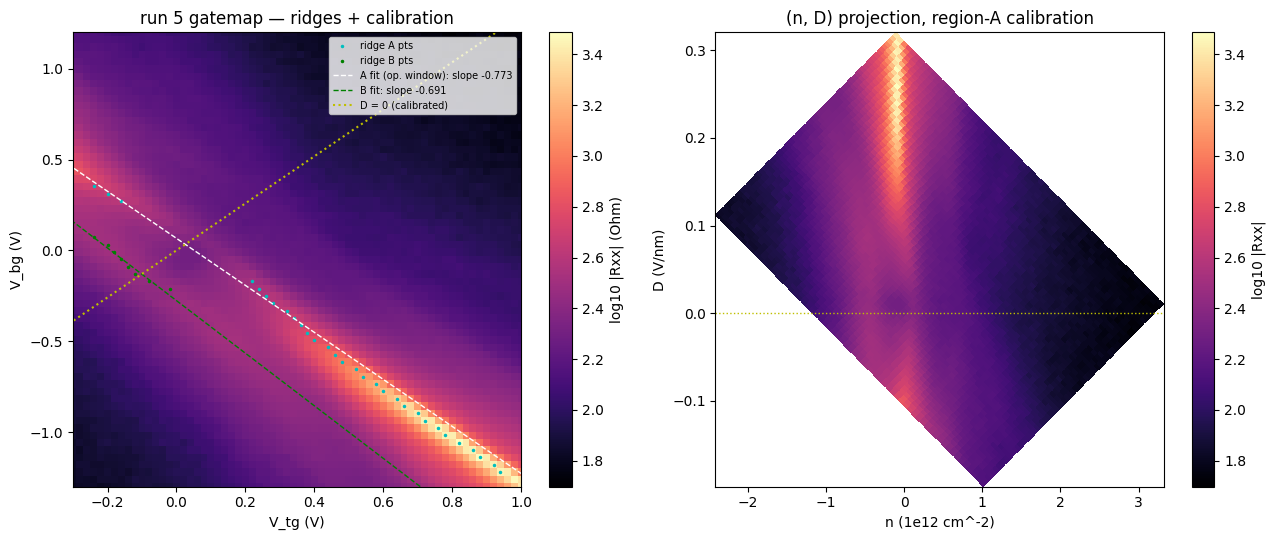

R_CNP(D) minimum: 297 Ohm at raw D = +0.048; parabola vertex raw D = +0.0130 V/nm -> D_offset = -0.0130


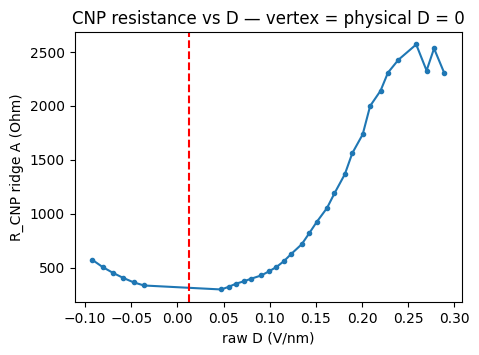

In [7]:
"""cnp-and-dline-calibration on gatemap run 5: per-row ridge extraction (two ridges), ratio fit on the
operating window near D = 0, offsets, closure check, realized D = 0 n-window; writes cal params to JSON."""
import json
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

rid = 5
g = fan_grids(str(Path(file_path) / str(rid))); rg = resistance_grids(g)
R = np.abs(rg.R["sr1"]); Vbg = g.slow
fs = g.meta["fast_setpoints"]; Vtg = np.asarray(fs[0] if isinstance(fs[0], list) else fs)
c_tg0 = stack_capacitance([(9.5, 3)]); c_bg0 = stack_capacitance([(11, 3)])
print(f"run {rid}: {g.nrows} rows x {g.nfast}; R {R.min():.0f}-{R.max():.0f} Ohm; prior c_bg/c_tg = {c_bg0/c_tg0:.3f}")

# ridge extraction: per row, up to two peaks; track continuity from the high-|D| end where ridge A is unambiguous
pts = []   # (Vbg, Vtg, R, ridge)
for i in range(g.nrows):
    r = gaussian_filter1d(R[i], 1.0)
    pk, _ = find_peaks(r, prominence=0.05 * (r.max() - r.min()) + 5)
    pk = [p for p in pk if 1 < p < g.nfast - 2]
    for p in sorted(pk, key=lambda p: -r[p])[:2]:
        pts.append((Vbg[i], Vtg[p], r[p]))
pts = np.array(pts)
# assign to ridges by distance to the high-D fit of ridge A (rows Vbg < -0.6), then refit each
selA = pts[:, 0] < -0.6
cfA0 = np.polyfit(pts[selA, 0], pts[selA, 1], 1)
dist = pts[:, 1] - np.polyval(cfA0, pts[:, 0])
ridgeA = pts[np.abs(dist) < 0.08]; ridgeB = pts[(dist < -0.08) & (dist > -0.45)]

def fit(p, lo, hi, label):
    m = (p[:, 0] >= lo) & (p[:, 0] <= hi)
    x, y = p[m, 0], p[m, 1]
    if len(x) < 4: print(f"{label}: {len(x)} rows, skip"); return None
    keep = np.ones(len(x), bool)
    for _ in range(3):
        cf = np.polyfit(x[keep], y[keep], 1); res = y - np.polyval(cf, x)
        keep = np.abs(res) < 2.5 * max(np.std(res[keep]), 0.01)
    cf = np.polyfit(x[keep], y[keep], 1); res = (y - np.polyval(cf, x))[keep]
    print(f"{label}: {keep.sum()}/{len(x)} rows, Vbg [{lo:+.2f},{hi:+.2f}]: Vtg = {cf[0]:+.4f} Vbg {cf[1]:+.4f}; "
          f"c_bg/c_tg = {-cf[0]:.3f}; rms {np.std(res)*1e3:.1f} mV")
    return cf

print("--- ridge A (main) ---")
cfA_all = fit(ridgeA, -2, 2, "A all rows")
cfA_hiD = fit(ridgeA, -2, -0.6, "A high-D rows")
cfA_op = fit(ridgeA, -0.5, 0.5, "A operating window |Vbg|<0.5")
print("--- ridge B (parallel, lower Vtg) ---")
cfB_all = fit(ridgeB, -2, 2, "B all rows")
cfB_op = fit(ridgeB, -0.5, 0.5, "B operating window")

# calibration: anchor c_tg at the prior (single hBN dielectric, better constrained), set c_bg from the operating-window ratio
cf = cfA_op if cfA_op is not None else cfA_all
ratio = -cf[0]; c_tg = c_tg0; c_bg = ratio * c_tg
n0, _ = calc_nD(cf[1], 0.0, c_tg, c_bg); n_offset = -n0
nA_ridge = calc_nD(np.polyval(cf, ridgeA[:, 0]), ridgeA[:, 0], c_tg, c_bg, n_offset=n_offset)[0]
print(f"\nCALIBRATION (ridge A, operating window): ratio {ratio:.3f} (prior {c_bg0/c_tg0:.3f}, {100*(ratio/(c_bg0/c_tg0)-1):+.0f}%), "
      f"c_tg {c_tg:.3e} F/m2 (prior anchor), c_bg {c_bg:.3e}; n_offset {n_offset:+.4f}e12; closure max|n| on fitted line {np.abs(nA_ridge).max():.3f}e12")
nB = calc_nD(ridgeB[:, 1], ridgeB[:, 0], c_tg, c_bg, n_offset=n_offset)[0] if len(ridgeB) else np.array([np.nan])
print(f"ridge B density offset relative to A: n_B = {np.nanmedian(nB):+.3f}e12 (std {np.nanstd(nB):.3f}), i.e. region B is {'hole' if np.nanmedian(nB)>0 else 'electron'}-doped vs A by {abs(np.nanmedian(nB)):.2f}e12")
# D = 0 line of region A: V_tg = (c_bg/c_tg) V_bg + V_tg0 where n=0 at ... use calc_gate_voltages
ns = np.linspace(-1.5, 4.5, 601); Vt, Vb = calc_gate_voltages(ns, np.zeros_like(ns), c_tg, c_bg, n_offset=n_offset)
ok = (Vt >= -0.3) & (Vt <= 1.0) & (Vb >= -1.3) & (Vb <= 2.0)
print(f"D = 0 line (region A) realized n-window inside validators: {ns[ok].min():+.2f} .. {ns[ok].max():+.2f} e12; "
      f"CNP at (Vtg, Vbg) = ({calc_gate_voltages(0,0,c_tg,c_bg,n_offset=n_offset)[0]:+.3f}, {calc_gate_voltages(0,0,c_tg,c_bg,n_offset=n_offset)[1]:+.3f})")
# D range along ridge A
DA = calc_nD(ridgeA[:, 1], ridgeA[:, 0], c_tg, c_bg, n_offset=n_offset)[1]
print(f"ridge A spans D = {DA.min():+.3f} .. {DA.max():+.3f} V/nm; peak R vs D: " +
      ", ".join(f"{d:+.2f}:{r:.0f}" for d, r in sorted(zip(np.round(DA, 2), ridgeA[:, 2]))[::6]))
json.dump({"run": rid, "ratio": ratio, "c_tg": c_tg, "c_bg": c_bg, "n_offset": n_offset, "D_offset": float(-D0_raw) if "D0_raw" in globals() else 0.0,
           "slope": cf[0], "intercept": cf[1], "window": "A |Vbg|<0.5", "nB_offset": float(np.nanmedian(nB))},
          open(Path(file_path).parent / "hera_scratch" / "cal_run5.json", "w"), indent=1)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
m = ax[0].pcolormesh(Vtg, Vbg, np.log10(R), shading="nearest", cmap="magma"); fig.colorbar(m, ax=ax[0], label="log10 |Rxx| (Ohm)")
ax[0].plot(ridgeA[:, 1], ridgeA[:, 0], "c.", ms=3, label="ridge A pts"); ax[0].plot(ridgeB[:, 1], ridgeB[:, 0], "g.", ms=3, label="ridge B pts")
xx = np.array([Vbg.min(), Vbg.max()])
ax[0].plot(np.polyval(cf, xx), xx, "w--", lw=1, label=f"A fit (op. window): slope {cf[0]:+.3f}")
if cfB_all is not None: ax[0].plot(np.polyval(cfB_all, xx), xx, "g--", lw=1, label=f"B fit: slope {cfB_all[0]:+.3f}")
ax[0].plot(Vt[ok], Vb[ok], "y:", lw=1.5, label="D = 0 (calibrated)")
ax[0].set_xlim(Vtg.min(), Vtg.max()); ax[0].set_ylim(Vbg.min(), Vbg.max()); ax[0].set_xlabel("V_tg (V)"); ax[0].set_ylabel("V_bg (V)")
ax[0].legend(fontsize=7, loc="upper right"); ax[0].set_title(f"run {rid} gatemap — ridges + calibration")
# (n, D) projection
N, D = calc_nD(Vtg[None, :], Vbg[:, None], c_tg, c_bg, n_offset=n_offset)
m2 = ax[1].pcolormesh(N, D, np.log10(R), shading="nearest", cmap="magma"); fig.colorbar(m2, ax=ax[1], label="log10 |Rxx|")
ax[1].axhline(0, color="y", ls=":", lw=1); ax[1].set_xlabel("n (1e12 cm^-2)"); ax[1].set_ylabel("D (V/nm)"); ax[1].set_title("(n, D) projection, region-A calibration")
fig.tight_layout(); plt.show()

# D_offset from the CNP-resistance symmetry in ±D (ridge A only, n within 0.1e12 of the fit line)
rows = []
for i in range(g.nrows):
    vc = cf[0] * Vbg[i] + cf[1]
    if vc < Vtg.min() + 0.03 or vc > Vtg.max() - 0.03: continue
    msk = np.abs(Vtg - vc) < 0.12
    r = gaussian_filter1d(R[i], 1.0); j = np.argmax(np.where(msk, r, -1))
    n_j, D_j = calc_nD(Vtg[j], Vbg[i], c_tg, c_bg, n_offset=n_offset)
    if abs(n_j) < 0.1: rows.append((D_j, r[j]))
rows = np.array(sorted(rows)); k = np.argmin(rows[:, 1]); sel = np.abs(rows[:, 0] - rows[k, 0]) < 0.12
cq = np.polyfit(rows[sel, 0], rows[sel, 1], 2); D0_raw = -cq[1] / (2 * cq[0])
print(f"R_CNP(D) minimum: {rows[k,1]:.0f} Ohm at raw D = {rows[k,0]:+.3f}; parabola vertex raw D = {D0_raw:+.4f} V/nm -> D_offset = {-D0_raw:+.4f}")
plt.figure(figsize=(5, 3.5)); plt.plot(rows[:, 0], rows[:, 1], "o-", ms=3); plt.axvline(D0_raw, color="r", ls="--")
plt.xlabel("raw D (V/nm)"); plt.ylabel("R_CNP ridge A (Ohm)"); plt.title("CNP resistance vs D — vertex = physical D = 0"); plt.show()


## Runs 6 & 7 — SdH spot checks at D = 0 (`sdh-spot-check`): electron n = +3.2e12 (B 0→10 T), hole n = −1.2e12 (10→0.3 T)


run 6
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    electron side: n = +3.20e12 cm^-2, D = +0.00 V/nm; (Vtg, Vbg) = (+0.9836, +1.1661); B 0 -> 10 T uniform-B (50 mT to 1 T, 10 mT above); cal run 5: ratio 0.773, n_offset -0.089e12, D_offset -0.013
  rows:    921 of 921 (complete)
  swept:   magnet_field 0 → 10 (monotonic)
run 7
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    hole side: n = -1.20e12 cm^-2, D = +0.00 V/nm; (Vtg, Vbg) = (-0.2770, -0.4650); B 10 -> 0.3 T uniform-B 20 mT (ride-down); cal run 5: ratio 0.773, n_offset -0.089e12, D_offset -0.013
  rows:    486 of 486 (complete)
  swept:   magnet_field 10 → 0.3 (monotonic)


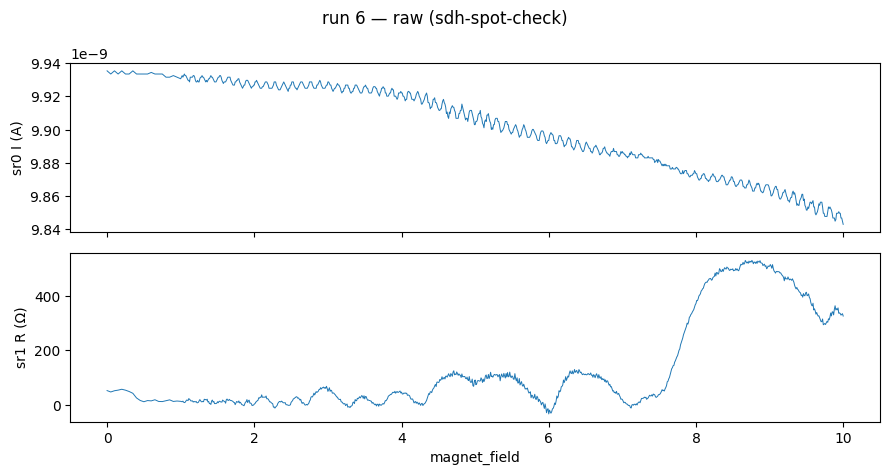

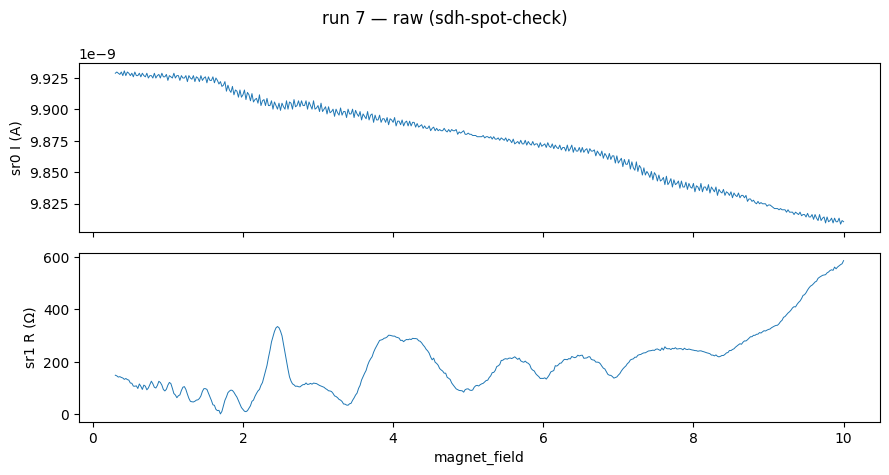

In [4]:
# Runs 6 & 7 — raw: sdh-spot-check at D = 0 (run-5 cal), sr1 = Rxx (B_1-B_2), I_bias 10 nA
for i in (6, 7):
    g = run(i)
    print(summarize_run(g))
    plot_raw(g)


run 6 FFT peaks (F, rel amp): (1.8 T, 1.00), (14.1 T, 0.35), (30.0 T, 0.31), (58.2 T, 0.06)
sdh_onset: onset_b = 0.30 T (tone 7.1 T) over B [0.30, 10.00] T
  tone    7.1 T: onset  0.30 T  dF  0.31 T  snr_max   40.2  [censored@edge, 2x->14.1T, 3x->22.1T, 4x->29.5T]
  tone   22.1 T: onset  1.36 T  dF  1.57 T  snr_max   37.1  [~3x7.1T]
  tone   14.1 T: onset  1.62 T  dF  1.93 T  snr_max   52.5  [revives-below-gap, ~2x7.1T]
  tone   29.5 T: onset  1.91 T  dF  2.36 T  snr_max   89.0  [~4x7.1T]
  tone    3.0 T: onset  0.30 T  dF  0.31 T  snr_max   59.9  [censored@edge, near-residual]
  tone    9.5 T: onset  0.30 T  dF  0.31 T  snr_max   21.8  [censored@edge]
  tone    4.2 T: onset  0.30 T  dF  0.31 T  snr_max   33.7  [censored@edge]
  tone    5.1 T: onset  0.30 T  dF  0.31 T  snr_max   48.7  [censored@edge]

run 7 FFT peaks (F, rel amp): (5.3 T, 1.00), (21.2 T, 0.14)
sdh_onset: onset_b = 0.71 T (tone 6.6 T) over B [0.30, 10.00] T
  tone    6.6 T: onset  0.71 T  dF  0.77 T  snr_max   83.8  [~

/tmp/ipykernel_49/1021721401.py:37: UserWarning: sdh_onset: tone 7.1 T is above threshold through the lowest window — oscillations persist to the record's low edge; onset_b = 0.30 T is the record edge, not a measured die-off
  so = sdh_onset(R, B, b_lo=0.3, r_full_scale=50e-6 / Imed)
/tmp/ipykernel_49/1021721401.py:37: UserWarning: sdh_onset: untracked tone(s): 3.4 T (never above threshold (max SNR 3.6 vs 5 across 3 windows))
  so = sdh_onset(R, B, b_lo=0.3, r_full_scale=50e-6 / Imed)


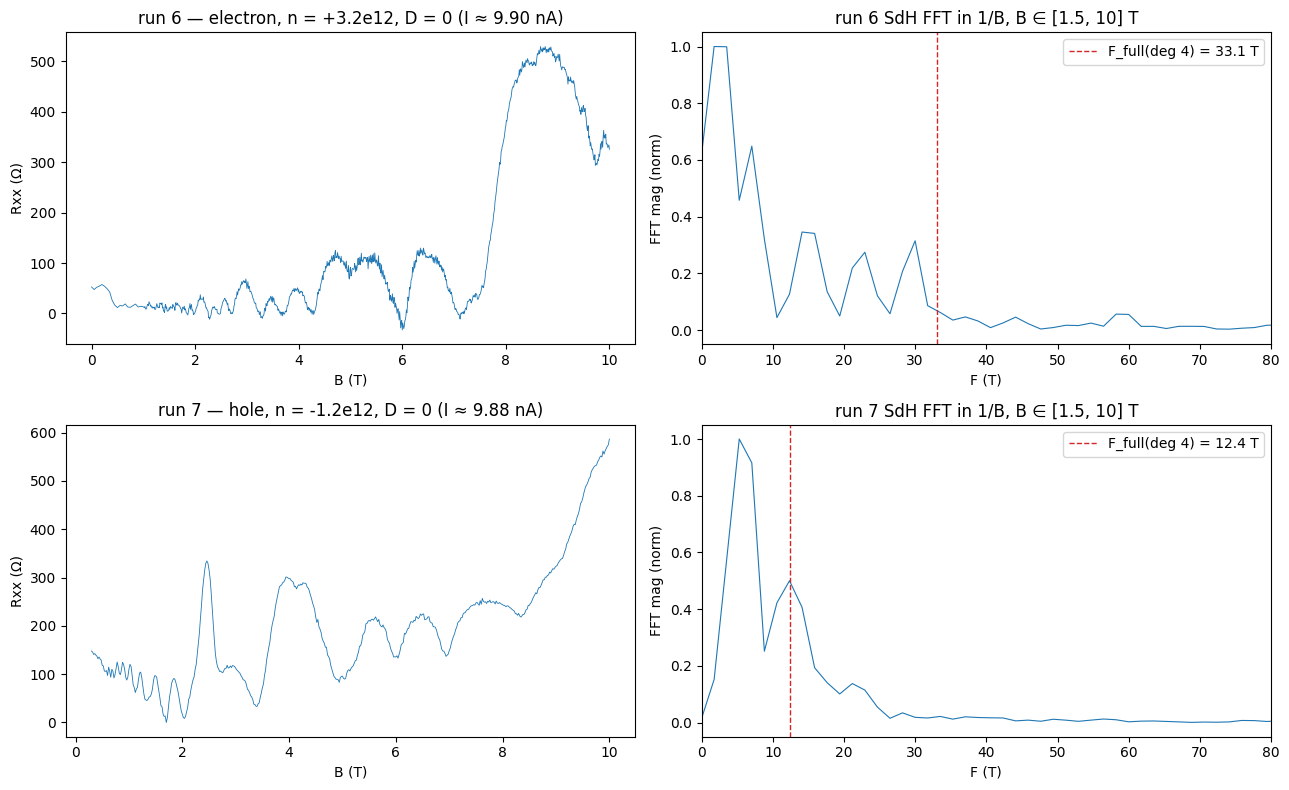

In [5]:
# Runs 6 & 7 — SdH content: Rxx(B), FFT in 1/B (B in [1.5, 10] T), per-tone onsets.
from hera.analysis import resolve_channels, current_channel, sdh_onset, SdhOnsetError
from scipy.signal import find_peaks

H_OVER_E = cst.h / cst.e

def rxx_vs_B(i):
    g = run(i)
    ch = resolve_channels(g.meta)
    cur = current_channel(ch)
    I = g.col(cur.col) / cur.gain
    v = [c for c in ch if c.cid == "sr1"][0]
    R = (g.col(v.col) / v.gain) / I
    B = g.col("magnet_field")
    o = np.argsort(B)
    return B[o], R[o], np.median(np.abs(I))

fig, axs = plt.subplots(2, 2, figsize=(13, 8))
for row, (i, n12, tag) in enumerate([(6, +3.2, "electron"), (7, -1.2, "hole")]):
    B, R, Imed = rxx_vs_B(i)
    F_full = H_OVER_E * abs(n12) * 1e16 / 4  # single 4-fold FS carrying all of n
    ax = axs[row, 0]
    ax.plot(B, R, lw=0.6)
    ax.set_xlabel("B (T)"); ax.set_ylabel("Rxx (Ω)")
    ax.set_title(f"run {i} — {tag}, n = {n12:+.1f}e12, D = 0 (I ≈ {Imed*1e9:.2f} nA)")
    freqs, spec = sdh_fft(R[:, None], B, b_range=(1.5, 10.0), nfft=4096, bg_degree=5, log=False)
    sp = spec[0]
    ax2 = axs[row, 1]
    ax2.plot(freqs, sp / sp.max(), lw=0.8)
    ax2.axvline(F_full, color="tab:red", ls="--", lw=1, label=f"F_full(deg 4) = {F_full:.1f} T")
    ax2.set_xlim(0, 80); ax2.set_xlabel("F (T)"); ax2.set_ylabel("FFT mag (norm)"); ax2.legend()
    ax2.set_title(f"run {i} SdH FFT in 1/B, B ∈ [1.5, 10] T")
    pk, _ = find_peaks(sp, height=0.05 * sp.max(), distance=5)
    top = sorted(zip(freqs[pk], sp[pk]), key=lambda t: -t[1])[:6]
    print(f"run {i} FFT peaks (F, rel amp): " + ", ".join(f"({f:.1f} T, {a/sp.max():.2f})" for f, a in top))
    try:
        so = sdh_onset(R, B, b_lo=0.3, r_full_scale=50e-6 / Imed)
        print(so.summary())
    except SdhOnsetError as e:
        print(f"run {i} sdh_onset: {e}")
    print()
fig.tight_layout()


**Read (runs 6 & 7, `data/6` `data/7`):**

- **Run 6 (electron, n = +3.2×10¹², F_full = 33.1 T):** one dominant *light* fundamental **F ≈ 7.1 T** (onset < 0.3 T, SNR 40+), with its 2×/3×/4× harmonics (14.1 / 22.1 / 29.5 T). 7.1 T is only ~21 % of F_full → **the light Fermi surface carries a minority of the density; a second, heavier band must hold the remaining ~26 T** — invisible or nearly so at T_e ≈ 8 K (LK damping at m* ≈ 0.06 mₑ leaves ~1 % amplitude at 10 T), and spectrally degenerate with 4×7.1 = 28.4 T where the 29.5 T tone sits. The giant Rxx rise above ~7.5 T is the light band entering its lowest Landau levels. Consistent with the **ABAB light/heavy pair (predicted ≈ 7.5 / 25.6 T)**; inconsistent with a single-band ABCA read (one 33 T fundamental, absent).
- **Run 7 (hole, n = −1.2×10¹², F_full = 12.4 T):** two **non-harmonically-related fundamentals ≈ 4.7 T and 6.6 T**, sum ≈ 11.3 T ≈ F_full → a two-Fermi-surface hole side with near-balanced densities, close to the ABAB near-CNP pair prediction (5.3 / 7.1 T). An ABCA heavy single band (m* ~ 1 mₑ) would be LK-dead here — the *presence* of strong low-onset oscillations is itself evidence against it.

**Take:** both spot checks point at **ABAB (Bernal)** — a two-band Fermiology on both carrier signs with a light+heavy split on the electron side. Not yet a call: a single-density FFT cannot separate "4th harmonic of 7.1 T" from "heavy band at ~26–30 T", and ABCB (Dirac + bilayer-like pair) is not excluded by frequency sums alone. The discriminator is the **Landau fan at D = 0**: each band's LL minima form straight fans in (n, B) with slopes ∝ 1/band-density-fraction — a heavy band appears as its own fan and produces crossings with the light-band fan; harmonics instead track the same fan. → next: `landau-fan`, n ∈ [−1.2, +3.2]×10¹² along D = 0, B 0.5 → 10 T.
